# Task 1 · Part 3 — Feature Checklist: Inspection, Statistics, Trends, Heatmap and Conclusions
This notebook completes the project checklist on the cleaned table from `01_cleaning_and_features.ipynb`. It covers:
1. Initial inspection (shape, dtypes, nulls) · 2. Descriptive statistics · 3. Monthly and quarterly trend lines · 4. Customer age and gender distribution · 5. Top 10 best-selling products and revenue by category · 6. Correlation heatmap · 7. An additional chart revealing a non-obvious insight · 8. Observations after every chart · 9. Conclusions and recommendations.

The six business questions are answered in depth in `02_business_questions.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from pathlib import Path

OUT = Path("../outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False,
})
def money(x, pos=None):
    return f"{x/1e6:.1f}M" if abs(x) >= 1e6 else (f"{x/1e3:.0f}k" if abs(x) >= 1e3 else f"{x:.0f}")
def money2(x):
    return f"{x/1e6:.2f}M" if abs(x) >= 1e6 else money(x)
MONEY = FuncFormatter(money)
def style(ax, grid="y"):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(axis=grid, color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
def save(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

df = pd.read_csv(OUT / "retail_clean.csv", parse_dates=["Date", "BirthDate", "JoinDate"])

## 1. Initial inspection: shape, data types, missing values

In [2]:
print("Shape:", df.shape, "→", f"{df.shape[0]:,} transactions × {df.shape[1]} columns")
inspect = pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(), "unique": df.nunique()})
inspect

Shape: (5000, 36) → 5,000 transactions × 36 columns


,dtype,nulls,unique
TransactionID,str,0,5000
Date,datetime64[us],0,729
CustomerID,str,0,200
ProductID,str,0,50
StoreID,str,0,5
Quantity,int64,0,5
Discount,float64,0,4
PaymentMethod,str,0,4
ProductName,str,0,50
Category,str,0,3


**Observation.** The merged table has 5,000 rows and 36 columns (the 8 transaction columns, product, customer and store details, plus the features built in Part 1). There are **no missing values** in any column, dates are real datetimes, and IDs/categories are text. `CustomerCity` has 200 unique values for 200 customers, which means every customer lives in a different city (this limits any geographic analysis).

## 2. Descriptive statistics: mean, median, mode, standard deviation

In [3]:
num_cols = ["Quantity", "Discount", "UnitPrice", "CostPrice", "GrossSales", "DiscountAmount",
            "Revenue", "TotalCost", "Profit", "ProfitMargin", "Age"]
stats_tbl = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
stats_tbl["mode"] = [df[c].mode().iloc[0] for c in num_cols]
stats_tbl = stats_tbl[["mean", "median", "mode", "std", "min", "max"]]
stats_tbl

,mean,median,mode,std,min,max
Quantity,2.99,3.00,2.00,1.41,1.00,5.00
Discount,0.08,0.10,0.15,0.06,0.00,0.15
UnitPrice,"1,036.61","1,193.09","1,134.80",589.32,25.57,"1,952.65"
CostPrice,702.00,794.80,675.10,426.69,15.28,"1,451.27"
GrossSales,"3,095.03","2,386.18","1,879.08","2,435.65",25.57,"9,763.25"
DiscountAmount,234.65,128.41,0.00,285.74,0.00,"1,464.49"
Revenue,"2,860.38","2,156.12","4,267.91","2,265.96",21.73,"9,763.25"
TotalCost,"2,095.12","1,582.86","1,004.56","1,717.60",15.28,"7,256.35"
Profit,765.26,555.11,297.77,711.18,2.68,"4,372.60"
ProfitMargin,0.28,0.27,0.25,0.11,0.06,0.50


**Observation.**
- A typical order is **3 units** (mean 2.99, median 3, spread 1.4; mode 2), so quantity is spread evenly between 1 and 5.
- **Revenue per order is right-skewed:** mean 2,860 is well above the median 2,156 because of large orders up to 9.8k. Profit shows the same pattern (mean 765 vs median 555).
- The **most common discount is 15%** (mode), but the average is 7.6%; discounts are spread almost evenly over 0, 5, 10 and 15%.
- Profit margin averages about 28% (median 26.5%) and ranges from 6% to 50%, so some products earn far more per sale than others.
- Customers are aged **16–70 on the order date** (mean 43, median 44).

## 3. Time series: monthly and quarterly sales trends

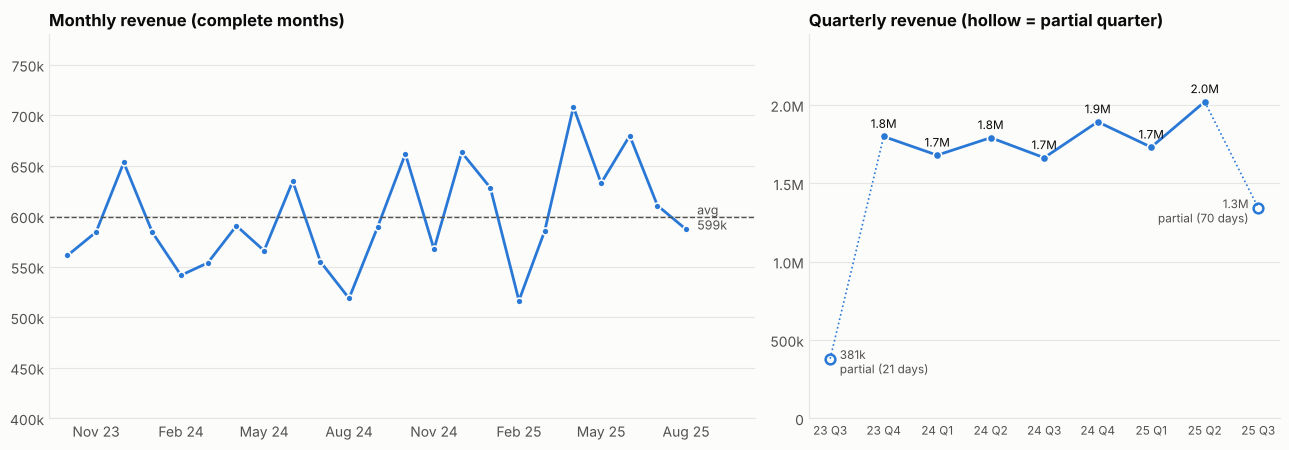

Complete-month revenue: min 516,524 | max 708,233 | mean 598,911


In [4]:
# Monthly line chart (complete months only; the first and last months are partial)
m = df.groupby("YearMonth").Revenue.sum().loc["2023-10":"2025-08"]
m.index = pd.to_datetime(m.index)
q = df.groupby("Quarter").Revenue.sum()
qdays = df.groupby("Quarter").Date.nunique()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [3, 2]})
a1.plot(m.index, m.values, color=BLUE, lw=2, marker="o", markersize=5, markeredgecolor=SURF, markeredgewidth=1.2)
a1.axhline(m.mean(), color=INK2, lw=1, ls="--"); a1.set_xlim(m.index[0] - pd.Timedelta(days=20), m.index[-1] + pd.Timedelta(days=75))
a1.text(m.index[-1] + pd.Timedelta(days=12), m.mean(), f"avg\n{money(m.mean())}", color=INK2, fontsize=9, va="center")
a1.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); a1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
a1.yaxis.set_major_formatter(MONEY); a1.set_ylim(400000, 780000)
a1.set_title("Monthly revenue (complete months)"); style(a1)

labels = [s[2:4] + " " + s[4:] for s in q.index]
full = [i for i, k in enumerate(q.index) if k not in ("2023Q3", "2025Q3")]
a2.plot(full, q.values[full], color=BLUE, lw=2, marker="o", markersize=6, markeredgecolor=SURF, markeredgewidth=1.2)
for i in (0, len(q) - 1):   # partial quarters: hollow markers, dashed link
    a2.plot([i], [q.values[i]], marker="o", markersize=7, markerfacecolor=SURF, markeredgecolor=BLUE, markeredgewidth=1.8, ls="")
a2.plot([0, 1], q.values[:2], color=BLUE, lw=1.2, ls=":"); a2.plot([len(q) - 2, len(q) - 1], q.values[-2:], color=BLUE, lw=1.2, ls=":")
for i, v in enumerate(q.values):
    if 0 < i < len(q) - 1: a2.text(i, v + 55000, money(v), ha="center", fontsize=8.5)
a2.text(0.18, q.values[0] - 20000, f"{money(q.values[0])}\npartial (21 days)", ha="left", va="center", fontsize=8.5, color=INK2)
a2.text(len(q) - 1.18, q.values[-1] - 20000, f"{money(q.values[-1])}\npartial (70 days)", ha="right", va="center", fontsize=8.5, color=INK2)
a2.set_xticks(range(len(q)), labels, fontsize=8.5); a2.yaxis.set_major_formatter(MONEY); a2.set_ylim(0, 2.45e6)
a2.set_title("Quarterly revenue (hollow = partial quarter)"); style(a2)
fig.tight_layout(); save(fig, "p3_monthly_quarterly_lines.png"); plt.show()
print("Complete-month revenue: min", f"{m.min():,.0f}", "| max", f"{m.max():,.0f}", "| mean", f"{m.mean():,.0f}")

**Observation.** Monthly revenue moves in a narrow band (about **517k to 708k, average 599k**), with the peak in April 2025 and the low in February 2025 (the shortest month). Full quarters run between **1.66M and 2.02M**, and the best quarter is 2025 Q2. The first and last quarters are partial (21 and 70 days of data), so their low totals are not a decline. Growth is gradual: Jan–Aug 2025 is 8.9% above Jan–Aug 2024.

## 4. Customer demographics: age groups and gender

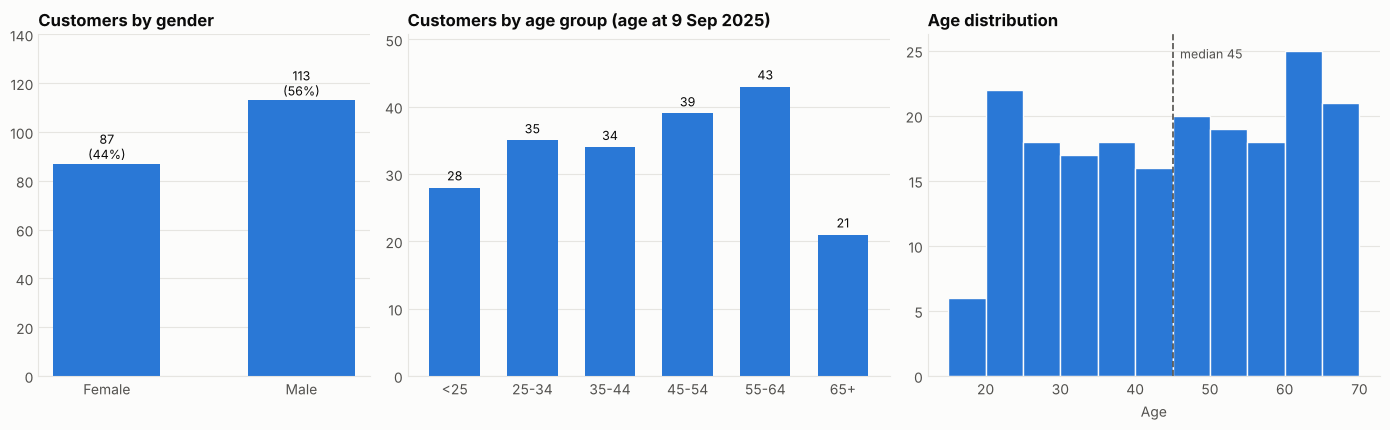

Revenue share: female 43.6%, male 56.4%
Age range: 18 - 70


In [5]:
# One row per customer; age on the last date in the data so each customer is in exactly one band
end = df.Date.max()
cust = df.groupby("CustomerID").agg(Gender=("Gender", "first"), BirthDate=("BirthDate", "first"),
                                    Revenue=("Revenue", "sum")).reset_index()
cust["Age"] = ((end - cust.BirthDate).dt.days // 365.25).astype(int)
cust["AgeBand"] = pd.cut(cust.Age, [0, 24, 34, 44, 54, 64, 120], labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])
age_counts = cust.AgeBand.value_counts().sort_index()
gender_counts = cust.Gender.value_counts()
gender_rev = df.groupby("Gender").Revenue.sum()

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 3.2, 3]})
a1.bar(["Female", "Male"], [gender_counts["F"], gender_counts["M"]], color=BLUE, width=0.55)
for i, v in enumerate([gender_counts["F"], gender_counts["M"]]):
    a1.text(i, v + 2, f"{v}\n({v/200:.0%})", ha="center", fontsize=9)
a1.set_ylim(0, 140); a1.set_title("Customers by gender"); style(a1)

b = a2.bar(age_counts.index.astype(str), age_counts.values, color=BLUE, width=0.65)
a2.bar_label(b, padding=3, fontsize=9); a2.set_ylim(0, age_counts.max() * 1.18)
a2.set_title("Customers by age group (age at 9 Sep 2025)"); style(a2)

a3.hist(cust.Age, bins=np.arange(15, 75, 5), color=BLUE, edgecolor=SURF, linewidth=1)
a3.axvline(cust.Age.median(), color=INK2, ls="--", lw=1.2)
a3.text(cust.Age.median() + 1, a3.get_ylim()[1] * 0.93, f"median {cust.Age.median():.0f}", color=INK2, fontsize=9)
a3.set_xlabel("Age"); a3.set_title("Age distribution"); style(a3)
fig.tight_layout(); save(fig, "p3_age_gender_distribution.png"); plt.show()
print(f"Revenue share: female {gender_rev['F']/gender_rev.sum():.1%}, male {gender_rev['M']/gender_rev.sum():.1%}")
print("Age range:", cust.Age.min(), "-", cust.Age.max())

**Observation.** The customer base is **56.5% male (113) and 43.5% female (87)**, and revenue splits almost the same way (56% / 44%), so each customer spends about the same (see Part 2, p = 0.93). Ages run from 18 to 70 and are spread broadly: the **55–64 group is the largest (43 customers)** and 65+ the smallest (21). There is no single dominant age group, so the business serves a wide range of adults.

## 5. Product analysis: top 10 best sellers and revenue by category

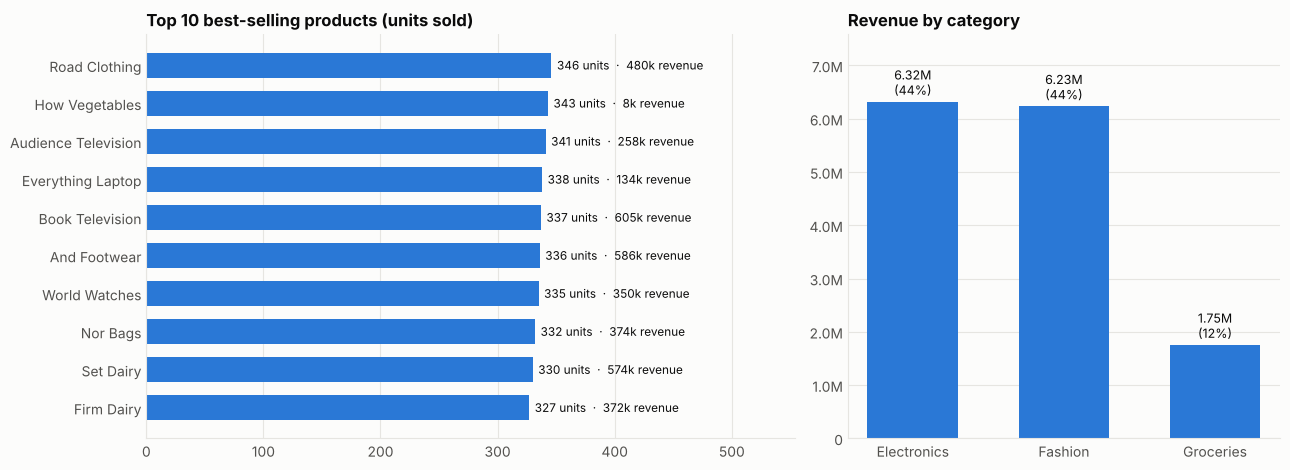

Top 10 products' share of all units sold: 22.5%
Units sold per product: min 225 | max 346 | mean 299


In [6]:
prod = df.groupby(["ProductName", "Category"]).agg(Units=("Quantity", "sum"), Revenue=("Revenue", "sum"),
                                                  Profit=("Profit", "sum")).reset_index()
top_units = prod.nlargest(10, "Units").sort_values("Units")
cat_rev = df.groupby("Category").Revenue.sum().sort_values(ascending=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [6, 4]})
b = a1.barh(top_units.ProductName, top_units.Units, color=BLUE, height=0.65)
a1.bar_label(b, labels=[f"{u:,.0f} units  ·  {money(r)} revenue" for u, r in zip(top_units.Units, top_units.Revenue)], padding=4, fontsize=8.5)
a1.set_xlim(0, top_units.Units.max() * 1.6); a1.set_title("Top 10 best-selling products (units sold)"); style(a1, "x")

b = a2.bar(cat_rev.index, cat_rev.values, color=BLUE, width=0.6)
a2.bar_label(b, labels=[f"{money2(v)}\n({v/cat_rev.sum():.0%})" for v in cat_rev.values], padding=3, fontsize=9)
a2.yaxis.set_major_formatter(MONEY); a2.set_ylim(0, cat_rev.max() * 1.2); a2.set_title("Revenue by category"); style(a2)
fig.tight_layout(); save(fig, "p3_top10_products_category_revenue.png"); plt.show()
print("Top 10 products' share of all units sold:", f"{prod.nlargest(10, 'Units').Units.sum() / prod.Units.sum():.1%}")
print("Units sold per product: min", prod.Units.min(), "| max", prod.Units.max(), "| mean", round(prod.Units.mean()))

**Observation.** The best seller by units is *Road Clothing* (346 units), followed by *How Vegetables* (343) and *Audience Television* (341), but the **top 10 sell only 22.5% of all units**: demand is spread very evenly (each product sells between 225 and 346 units). By category, **Electronics (6.32M) and Fashion (6.23M) each bring in about 44% of revenue**, and Groceries 12%. Note that *How Vegetables* is the #2 seller by units yet earns only 8k in revenue, because it is the cheapest product (25.57). The next section explores this.

## 6. Correlation heatmap of the numerical variables

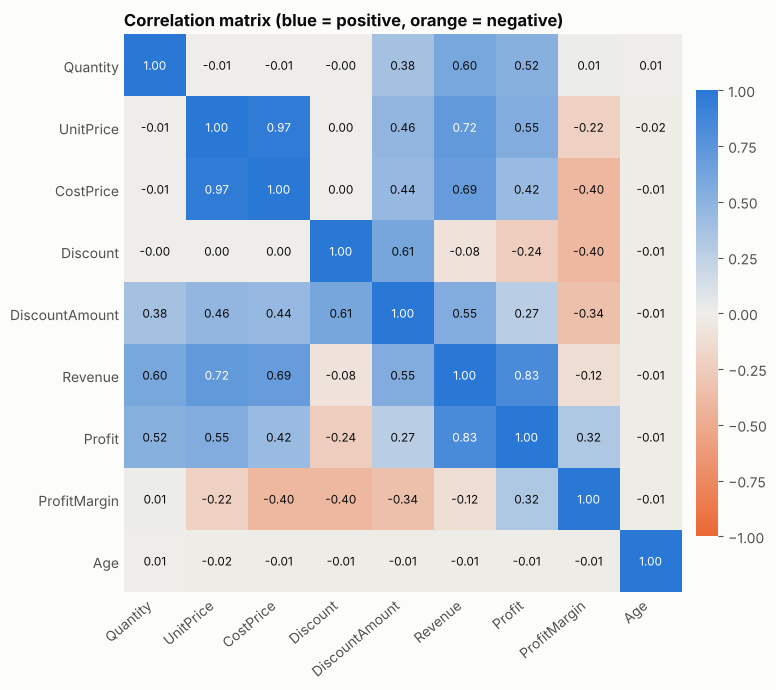

,Quantity,UnitPrice,CostPrice,Discount,DiscountAmount,Revenue,Profit,ProfitMargin,Age
Quantity,1.00,-0.01,-0.01,-0.00,0.38,0.60,0.52,0.01,0.01
UnitPrice,-0.01,1.00,0.97,0.00,0.46,0.72,0.55,-0.22,-0.02
CostPrice,-0.01,0.97,1.00,0.00,0.44,0.69,0.42,-0.40,-0.01
Discount,-0.00,0.00,0.00,1.00,0.61,-0.08,-0.24,-0.40,-0.01
DiscountAmount,0.38,0.46,0.44,0.61,1.00,0.55,0.27,-0.34,-0.01
Revenue,0.60,0.72,0.69,-0.08,0.55,1.00,0.83,-0.12,-0.01
Profit,0.52,0.55,0.42,-0.24,0.27,0.83,1.00,0.32,-0.01
ProfitMargin,0.01,-0.22,-0.40,-0.40,-0.34,-0.12,0.32,1.00,-0.01
Age,0.01,-0.02,-0.01,-0.01,-0.01,-0.01,-0.01,-0.01,1.00


In [7]:
corr_cols = ["Quantity", "UnitPrice", "CostPrice", "Discount", "DiscountAmount", "Revenue", "Profit", "ProfitMargin", "Age"]
corr = df[corr_cols].corr()
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#efeeea", BLUE])   # two hues + neutral midpoint
fig, ax = plt.subplots(figsize=(8.6, 7))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=40, ha="right"); ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.7 else INK)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0); cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02); cb.outline.set_visible(False)
ax.set_title("Correlation matrix (blue = positive, orange = negative)")
fig.tight_layout(); save(fig, "p3_correlation_heatmap.png"); plt.show()
corr.round(2)

**Observation.**
- **Price drives revenue, not quantity:** `Revenue` correlates strongly with `UnitPrice` (0.72) and moderately with `Quantity` (0.60), and `Profit` follows `Revenue` closely (0.83).
- **Discounts hurt margin:** `Discount` vs `ProfitMargin` is **−0.40**, tied with `CostPrice` as the strongest negative link in the table. `Discount` has essentially **zero correlation with `Quantity` (0.00)**, so deeper discounts do not make people buy more.
- `UnitPrice` and `CostPrice` move together (0.97), as expected, while higher-priced items have somewhat lower margins (−0.22).
- **Age is unrelated to everything** (all values within ±0.02), consistent with the finding that demographics do not drive spend.

## 7. Additional visualisation: the non-obvious insight — "best sellers" are really just the most expensive products
Rankings by revenue look like a popularity contest, but are they? I plot each product's **units sold** and **revenue** against its **unit price**.

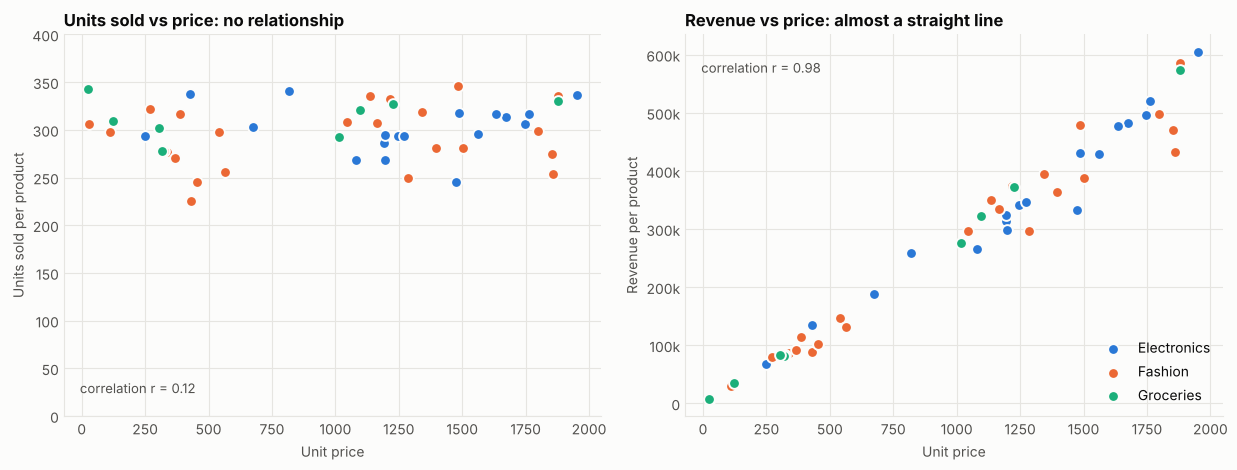

Units vs price: r = 0.12 | Revenue vs price: r = 0.98 | Revenue vs units: r = 0.28


In [8]:
p = df.groupby(["ProductName", "Category"]).agg(Units=("Quantity", "sum"), Revenue=("Revenue", "sum"),
                                               Price=("UnitPrice", "first")).reset_index()
colors = {"Electronics": BLUE, "Fashion": ORANGE, "Groceries": AQUA}
r_units, r_rev = p.Units.corr(p.Price), p.Revenue.corr(p.Price)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, col, title in [(a1, "Units", "Units sold vs price: no relationship"), (a2, "Revenue", "Revenue vs price: almost a straight line")]:
    for c, g in p.groupby("Category"):
        ax.scatter(g.Price, g[col], s=60, color=colors[c], edgecolor=SURF, linewidth=1.4, label=c, zorder=3)
    ax.set_xlabel("Unit price"); ax.set_title(title); style(ax, "both")
a1.set_ylim(0, 400); a1.set_ylabel("Units sold per product"); a1.text(0.03, 0.06, f"correlation r = {r_units:.2f}", transform=a1.transAxes, fontsize=9.5, color=INK2)
a2.yaxis.set_major_formatter(MONEY); a2.set_ylabel("Revenue per product"); a2.text(0.03, 0.9, f"correlation r = {r_rev:.2f}", transform=a2.transAxes, fontsize=9.5, color=INK2)
a2.legend(loc="lower right")
fig.tight_layout(); save(fig, "p3_price_drives_revenue.png"); plt.show()
print(f"Units vs price: r = {r_units:.2f} | Revenue vs price: r = {r_rev:.2f} | Revenue vs units: r = {p.Revenue.corr(p.Units):.2f}")

**Observation.** Every product sells roughly **300 units** whatever it costs (correlation with price only 0.12), but **revenue tracks price almost perfectly (r = 0.98)**. In other words, revenue rankings are really *price* rankings: a 1,950 television and a 25 vegetable pack are bought equally often, but one earns about 70 times more. So raw revenue is a poor guide to what customers want. **Margin and profit per unit** are better guides to which products deserve shelf space and promotion, and since volume does not respond to price, there may be room to raise the prices of popular low-priced items.

---
## 8. Conclusions and recommendations
**What the data says**
- The business is healthy and steady: **14.30M revenue, 3.83M profit (26.8% margin)** over 24 months, with like-for-like sales up 8.9% year on year.
- Performance is remarkably even: stores are within 6% of each other, products each sell about 300 units, and customers spend the same regardless of age or gender.
- The one clear lever is **discounting**: it costs 1.17M and does not change how much people buy, while margin falls from 32% to 21%.

**Recommendations**
1. **Test removing discounts, starting in one store.** Discounts reduced profit without raising units per order (Discount vs Quantity correlation 0.00). If volume holds at full price, profit could rise by up to about 30% (3.83M to 5.00M). Compare the test store with the other four for a few months before rolling out.
2. **Manage the range by profit per unit, not revenue.** Revenue mainly reflects price (r = 0.98), not popularity. Promote high-margin lines such as *And Footwear*, *Set Dairy* and *Him Smartphone* (40–42% margins) and review price or supplier cost for low-margin items such as laptops (20%), accessories (23%) and *Book Television* (19%).
3. **Grow through new customers and retention, not age or gender targeting.** Spend per customer is the same across demographics and customers already buy about 12.5 times a year, so the quickest route to growth is a larger customer base.
4. **Collect a customer region field and re-run the geographic analysis.** Each customer has a unique city, so demand by location cannot be measured today.
5. **Share practice from the best-performing store (New Michele).** It leads by only 6%, so the aim is to lift all stores slightly, not to fix a weak one.

**Caveats.** The data covers 24 months, 19.9% of transactions predate the customer's join date (flagged, not used), and the findings are observational: the discount result should be confirmed with a controlled test.